In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.integrate import solve_ivp

## Regular waves

We consider a single regular wave in this first case, and apply a simple theory to try to visualise the impact of vegetation (represented as thin rigid cylinder in this case)

wave length L: 22.19816866092418
Wave number k: 0.2830497147379543


Text(0, 0.5, 'eta (m)')

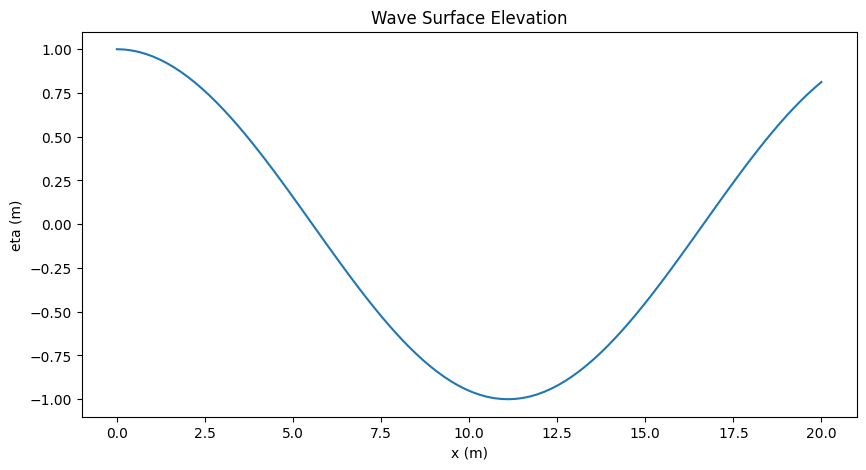

In [16]:
# def regular wave theory

g = 9.81
rho_w = 1000.0
H_0 = 2.0
T = 4.0
omega = 2 * np.pi / T
h = 5.0

def dispersion_relation(k, omega, h):
    return g * k * np.tanh(k * h) - omega**2

k = brentq(dispersion_relation, 1e-8, 10, args=(omega, h))
print('wave length L:', 2 * np.pi / k)
print('Wave number k:', k)
def eta(x,t,H):
    return H/2 * np.cos(k*x - omega*t)

def u(x,z,t, H):
    return (H/2) * omega * np.cosh(k*(z+h)) / np.sinh(k*h) * np.cos(k*x - omega*t)

def u_dot(x,z,t, H):
    return -(H/2) * omega**2 * np.cosh(k*(z+h)) / np.sinh(k*h) * np.sin(k*x - omega*t)


# plot wave
x_eta = np.linspace(0, 20, 100)
t_eta = 0

plt.figure(figsize=(10, 5))
plt.plot(x_eta, eta(x_eta, t_eta, H_0))
plt.title('Wave Surface Elevation')
plt.xlabel('x (m)')
plt.ylabel('eta (m)')


In [17]:
## there is vegetation on the ground, we a constant height of 1 m from x = 0 to x = 10m.
## we consider the vegetation as rigid cylinders with surface density of 100 cylinder per square meter, diameter of 0.1m.  
## The vegetation is located at the bottom of the water column, so we will consider the water depth to be 4 meters in the vegetated area.

### force due to the vegetation on the wave (drag force only) is given by the following formula:

C_D = 1.2 # drag coefficient for a vertical cylinder [adimensional]
C_M = 1.0 # inertia coefficient for a vertical cylinder [adimensional]
d = 0.1 # diameter of the cylinder [m]
h_vegetation = 1 # height of the vegetation [m]
n = 100 # number of cylinders per square meter [1/m^2]
L_vegetation = 50.0

Text(0, 0.5, 'Dissipation (W/m²)')

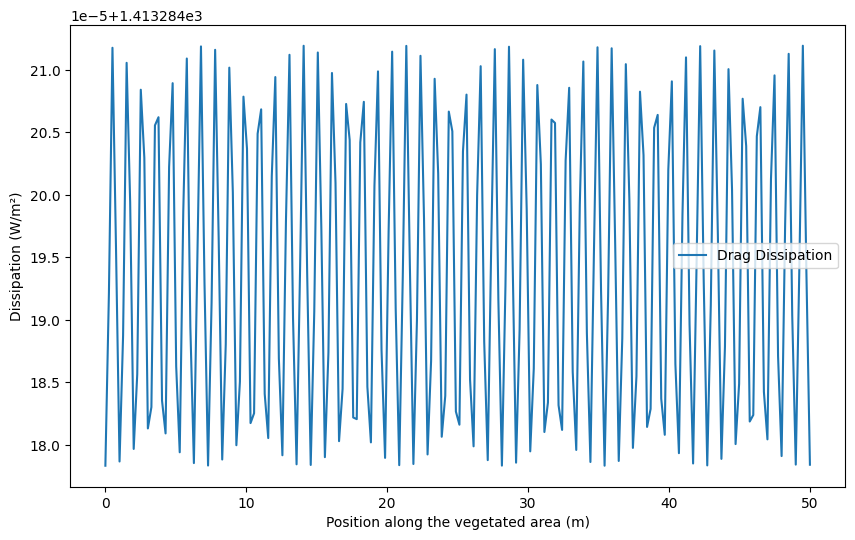

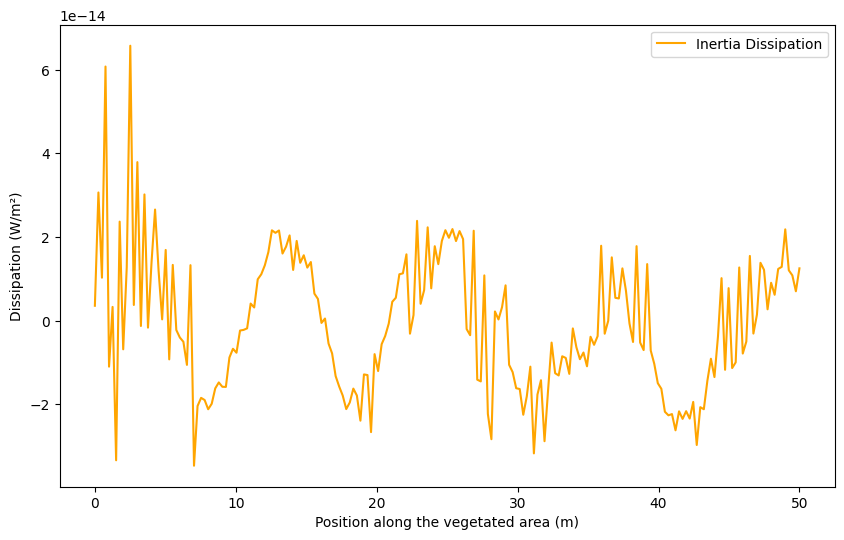

In [12]:
# We know the force due to the vegetation on the wave with the Morison equation. 
# we can calculate the impact on navier stokes equations and finally the impact on the wave height and period.

## From EnvMa_CM_2 (Centrale Nantes course), the energy per unit surface in the current case is:
## E = 1/8 * rho_w * g * H**2 

## We want to compute the dissipation due to the vegetation, which can be computed by the following formula:

### power dissipation per unit volume from drag force + inertia force to the fluid
### p_d = morison_equation(z,t) * u(x,z,t) = F_D = 0.5 * rho_vegetation * C_D * d * u_drag**2 +  F_I = rho_vege * C_M * np.pi * (d/2)**2 * u_dot(x, z, t)


def D_v(x, H):
    # we want to compute the dissipation due to the vegetation for a given x position in the vegetated area (0 < x < 10 m)
    # we will then integrate the power dissipation over the water column in the vegetated area
    # and over time for one period of the wave.

    z = np.linspace(-h, -h + h_vegetation, 100)
    t = np.linspace(0, T, 100)

    p_drag = np.zeros((len(z), len(t)))
    p_inertia = np.zeros((len(z), len(t)))

    for i in range(len(z)):
        for j in range(len(t)):

            velocity = u(x, z[i], t[j], H)
            acceleration = u_dot(x, z[i], t[j], H)

            # Force of water on vegetation per unit volume, Morison's equation
            F_D = 0.5 * rho_w * C_D * n * d * abs(velocity) * velocity
            F_I = rho_w * C_M * n * np.pi * (d/2)**2 * acceleration

            # Power extracted from water [W/m³]
            p_drag[i, j] = F_D * velocity
            p_inertia[i, j] = F_I * velocity

    # Average over one wave period
    mean_drag = np.trapezoid(p_drag, t, axis=1) / T
    mean_inertia = np.trapezoid(p_inertia, t, axis=1) / T

    # Integrate over vegetation height
    D_drag = np.trapezoid(mean_drag, z)
    D_inertia = np.trapezoid(mean_inertia, z)

    return D_drag, D_inertia

    
    
x = np.linspace(0, L_vegetation, 200)
D_drag = np.zeros_like(x)
D_inertia = np.zeros_like(x)

for i in range(len(x)):
    D_drag[i], D_inertia[i] = D_v(x[i], H_0)


plt.figure(figsize=(10, 6))
plt.plot(x, D_drag, label='Drag Dissipation')
plt.legend()
plt.xlabel('Position along the vegetated area (m)')
plt.ylabel('Dissipation (W/m²)')

plt.figure(figsize=(10, 6))
plt.plot(x, D_inertia, label='Inertia Dissipation', color='orange') 
plt.legend()
plt.xlabel('Position along the vegetated area (m)')
plt.ylabel('Dissipation (W/m²)')

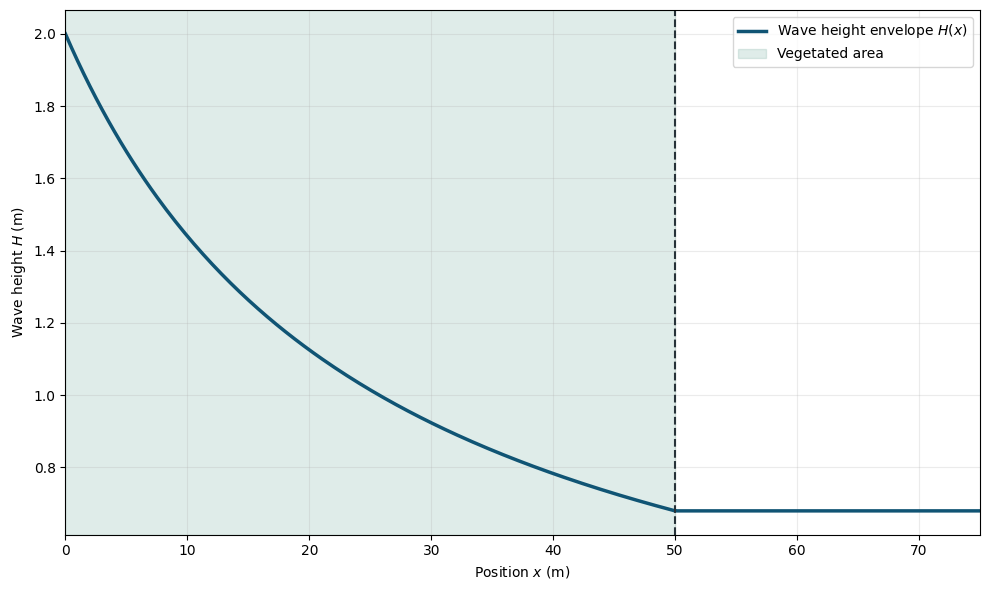

In [13]:
# Group velocity
cg = (omega / (2 * k)) * (
    1 + 2 * k * h / np.sinh(2 * k * h)
)

x_end = 1.5 * L_vegetation


def dH_dx(x, y):
    H_local = y[0]

    # No vegetation after x = L_vegetation:
    # the wave-height envelope remains constant.
    if x >= L_vegetation:
        return [0.0]

    D_drag, D_inertia = D_v(x, H_local)

    # Wave-energy balance
    return [
        -4 * D_drag / (rho_w * g * cg * H_local)
    ]


x_eval = np.linspace(0, x_end, 300)

solution = solve_ivp(
    dH_dx,
    (0, x_end),
    [H_0],
    t_eval=x_eval,
    method="RK45",
    rtol=1e-6,
    atol=1e-8
)

if not solution.success:
    raise RuntimeError(solution.message)

H_x = solution.y[0]


plt.figure(figsize=(10, 6))

plt.plot(
    solution.t,
    H_x,
    color="#105474",
    linewidth=2.5,
    label="Wave height envelope $H(x)$"
)

plt.axvspan(
    0,
    L_vegetation,
    color="#2e806c",
    alpha=0.15,
    label="Vegetated area"
)

plt.axvline(
    L_vegetation,
    color="#273239",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Position $x$ (m)")
plt.ylabel("Wave height $H$ (m)")
plt.xlim(0, x_end)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

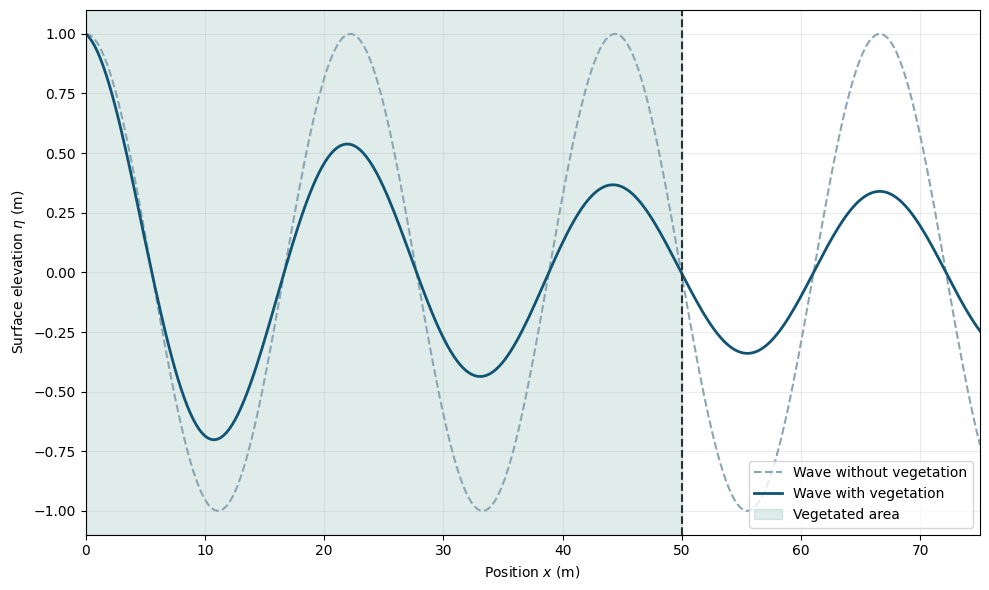

In [14]:
eta_initial = H_0 / 2 * np.cos(k * x_eval - omega * 0)
eta_attenuated = H_x / 2 * np.cos(k * x_eval - omega * 0)

plt.figure(figsize=(10, 6))

plt.plot(
    x_eval,
    eta_initial,
    linestyle="--",
    color="#8ba6b3",
    label="Wave without vegetation"
)

plt.plot(
    x_eval,
    eta_attenuated,
    color="#105474",
    linewidth=2,
    label="Wave with vegetation"
)

plt.axvspan(
    0,
    L_vegetation,
    color="#2e806c",
    alpha=0.15,
    label="Vegetated area"
)

plt.axvline(
    L_vegetation,
    color="#273239",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Position $x$ (m)")
plt.ylabel("Surface elevation $\\eta$ (m)")
plt.xlim(0, x_end)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

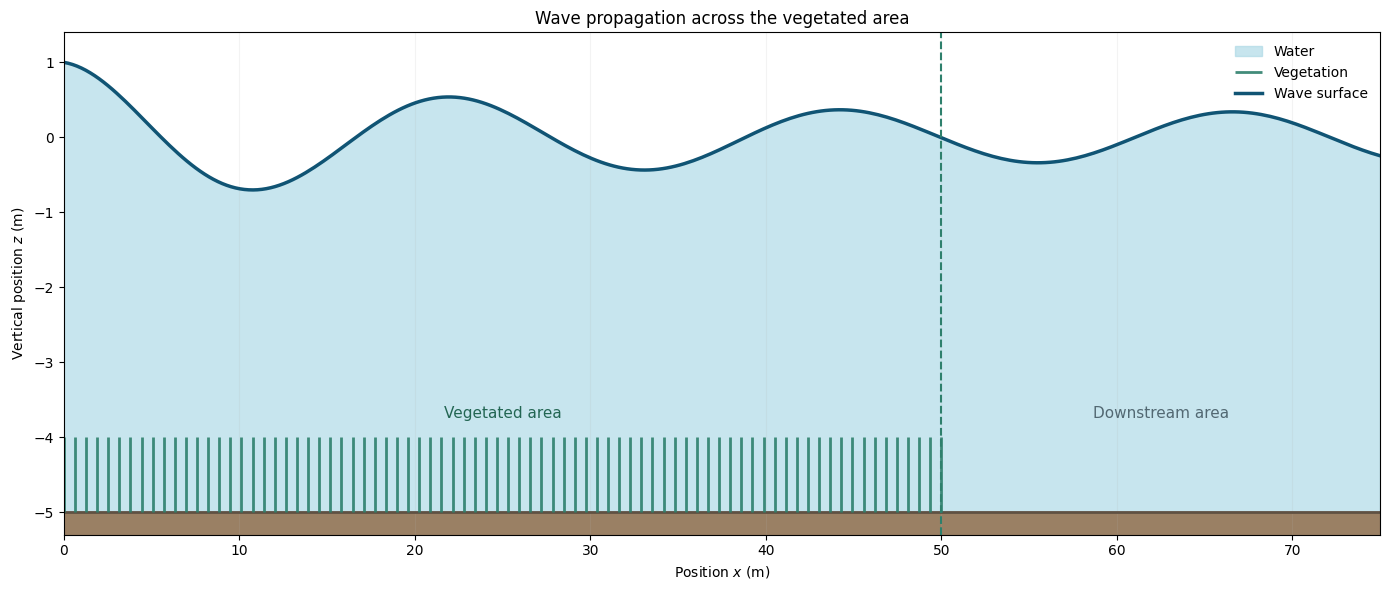

In [15]:
# Instantaneous wave surface
t_plot = 0.0

eta_attenuated = (
    H_x / 2
    * np.cos(k * x_eval - omega * t_plot)
)

# Positions used only to represent the vegetation
x_vegetation = np.linspace(
    0,
    L_vegetation,
    80
)

bed_level = -h
vegetation_top = -h + h_vegetation


fig, ax = plt.subplots(figsize=(14, 6))

# Water column
ax.fill_between(
    x_eval,
    bed_level,
    eta_attenuated,
    color="#a9d7e5",
    alpha=0.65,
    label="Water"
)

# Seabed
ax.fill_between(
    x_eval,
    bed_level - 0.3,
    bed_level,
    color="#9a8064"
)

ax.plot(
    x_eval,
    np.full_like(x_eval, bed_level),
    color="#5f5143",
    linewidth=2
)

# Vegetation represented by vertical green stems
ax.vlines(
    x_vegetation,
    ymin=bed_level,
    ymax=vegetation_top,
    color="#2e806c",
    linewidth=2,
    alpha=0.9,
    label="Vegetation"
)

# Free surface
ax.plot(
    x_eval,
    eta_attenuated,
    color="#105474",
    linewidth=2.5,
    label="Wave surface"
)

# End of the vegetated area
ax.axvline(
    L_vegetation,
    color="#2e806c",
    linestyle="--",
    linewidth=1.5
)

ax.text(
    L_vegetation / 2,
    vegetation_top + 0.25,
    "Vegetated area",
    color="#236653",
    ha="center",
    fontsize=11
)

ax.text(
    1.25 * L_vegetation,
    vegetation_top + 0.25,
    "Downstream area",
    color="#526872",
    ha="center",
    fontsize=11
)

ax.set_xlim(0, 1.5 * L_vegetation)
ax.set_ylim(bed_level - 0.3, 1.4)

ax.set_xlabel("Position $x$ (m)")
ax.set_ylabel("Vertical position $z$ (m)")
ax.set_title("Wave propagation across the vegetated area")

ax.grid(
    axis="x",
    alpha=0.15
)

ax.legend(
    loc="upper right",
    frameon=False
)

plt.tight_layout()
plt.show()

## Irregular waves 

We still consider a linear 2D case, but with irregular waves. We can still use the same theory developed before, but for irregular waves. 

We will then decompose the irregular waves and apply the theory with each component of it. 

In [56]:
## Define the incident irregular wave from a normalized JONSWAP spectrum.

def jonswap_spectrum(f, H_s, T_p):
    f_p = 1 / T_p
    gamma = 3.3

    sigma = np.where(
        f <= f_p,
        0.07,
        0.09
    )

    peak_shape = np.exp(
        -((f - f_p)**2)
        / (2 * sigma**2 * f_p**2)
    )

    S_f = (
        g**2
        / (2 * np.pi)**4
        * f**(-5)
        * np.exp(-1.25 * (f_p / f)**4)
        * gamma**peak_shape
    )

    # Enforce H_s = 4 * sqrt(m_0)
    target_m0 = (H_s / 4)**2
    current_m0 = np.trapezoid(S_f, f)
    S_f *= target_m0 / current_m0

    return S_f


def irregular_wave(x, t, H_s, T_p, N=100, seed=42):
    f_p = 1 / T_p

    f = np.linspace(
        0.2 * f_p,
        5 * f_p,
        N
    )

    df = f[1] - f[0]
    S_f = jonswap_spectrum(f, H_s, T_p)

    amplitudes = np.sqrt(
        2 * S_f * df
    )

    rng = np.random.default_rng(seed)

    phases = rng.uniform(
        0,
        2 * np.pi,
        N
    )

    omega_components = 2 * np.pi * f
    k_components = np.zeros(N)

    # eta has only its two physical dimensions: position and time
    eta = np.zeros(
        (
            len(x),
            len(t)
        )
    )

    for j in range(N):
        omega_j = omega_components[j]

        k_j = brentq(
            dispersion_relation,
            1e-8,
            10,
            args=(omega_j, h)
        )

        k_components[j] = k_j

        # theta_j has dimensions (x, time)
        theta_j = (
            k_j * x[:, None]
            - omega_j * t[None, :]
            + phases[j]
        )

        eta += (
            amplitudes[j]
            * np.cos(theta_j)
        )

    return eta, amplitudes, phases, f, k_components

eta shape: (200, 800)
component amplitudes: (100,)
initial Hs from the generated signal: 2.014111000573274


Text(0, 0.5, 'eta (m)')

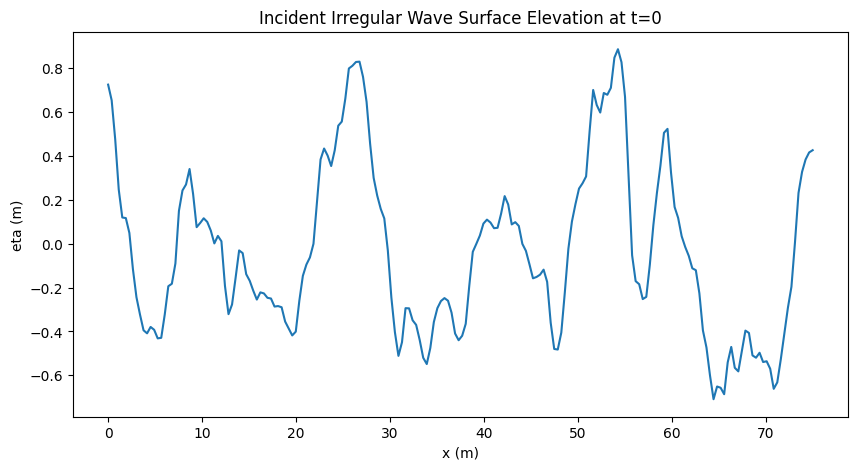

In [61]:
## Incident irregular-wave conditions and discretization.

H_s = 2.0
T_p = 4.0
N = 100

x_irregular = np.linspace(
    0,
    1.5 * L_vegetation,
    200
)

# Only the part of the water column occupied by vegetation is needed
z_vegetation = np.linspace(
    -h,
    -h + h_vegetation,
    40
)

# A time record is required to evaluate the nonlinear energy transfer.
# A single column of eta_xt can still be used to plot t = 0 s.
time_record = np.linspace(
    0,
    20 * T_p,
    800
)

eta_incident_xt, Amp, phi, f, k_components = irregular_wave(
    x_irregular,
    time_record,
    H_s,
    T_p,
    N,
    seed=77
)

omega_components = 2 * np.pi * f

cg_components = (
    omega_components / (2 * k_components)
    * (
        1
        + 2 * k_components * h
        / np.sinh(2 * k_components * h)
    )
)

print("eta shape:", eta_incident_xt.shape)
print("component amplitudes:", Amp.shape)
print("initial Hs from the generated signal:", 4 * np.std(eta_incident_xt[0, :]))

## plot incident irregular wave
plt.figure(figsize=(10, 5))
plt.plot(x_irregular, eta_incident_xt[:,0])
plt.title('Incident Irregular Wave Surface Elevation at t=0')
plt.xlabel('x (m)')
plt.ylabel('eta (m)')

In [ ]:
## We decompose the horizontal position in several tranche, we then evaluate the energy dissipation due to the vegetation 
## at each slice. We can then know the local surface elevation eta(x[i],t) for each i, and the reconstruct the whole surface elevation eta(x,t) at each time step.

dx = x_irregular[1] - x_irregular[0]
record_duration = time_record[-1] - time_record[0]

# Component amplitudes: one row per x and one column per frequency
amplitudes_x = np.zeros(
    (
        len(x_irregular),
        N
    )
)

amplitudes_x[0, :] = Amp

# Complete surface elevation: one row per x and one column per time
eta_xt = np.zeros(
    (
        len(x_irregular),
        len(time_record)
    )
)

D_total_profile = np.zeros_like(
    x_irregular
)


for i, x in enumerate(x_irregular):

    # Reconstruct eta(x[i],t) by adding every component
    for j in range(N):
        k_j = k_components[j]
        omega_j = omega_components[j]
        amplitude_j = amplitudes_x[i, j]
        phase_j = phi[j]

        theta_j = (
            k_j * x
            - omega_j * time_record
            + phase_j
        )

        eta_xt[i, :] += (
            amplitude_j
            * np.cos(theta_j)
        )


    # Amplitudes remain constant after the vegetation
    if x >= L_vegetation:
        amplitudes_x[i + 1, :] = amplitudes_x[i, :]
        continue

    # Total velocity in this slice: dimensions (z, time)
    u_total = np.zeros(
        (
            len(z_vegetation),
            len(time_record)
        )
    )

    # First pass: calculate the total irregular velocity
    for j in range(N):
        k_j = k_components[j]
        omega_j = omega_components[j]
        amplitude_j = amplitudes_x[i, j]
        phase_j = phi[j]

        theta_j = (
            k_j * x
            - omega_j * time_record
            + phase_j
        )

        vertical_profile_j = (
            np.cosh(
                k_j * (z_vegetation + h)
            )
            / np.sinh(k_j * h)
        )

        # u_j has only two dimensions: (z, time)
        u_j = (
            amplitude_j
            * omega_j
            * vertical_profile_j[:, None]
            * np.cos(theta_j)[None, :]
        )

        u_total += u_j

    # Nonlinear drag based on the total velocity
    F_drag = (
        0.5
        * rho_w
        * C_D
        * n
        * d
        * np.abs(u_total)
        * u_total
    )

## We now computed the non linear drag. Now, as the power is linear so we can evaluate the impact of the drag for each component separately. 
## we then do a second pass to project the drag power onto each component. 


    D_components = np.zeros(N)
    for j in range(N):
        k_j = k_components[j]
        omega_j = omega_components[j]
        amplitude_j = amplitudes_x[i, j]
        phase_j = phi[j]

        theta_j = (
            k_j * x
            - omega_j * time_record
            + phase_j
        )

        vertical_profile_j = (
            np.cosh(
                k_j * (z_vegetation + h)
            )
            / np.sinh(k_j * h)
        )

        u_j = (
            amplitude_j
            * omega_j
            * vertical_profile_j[:, None]
            * np.cos(theta_j)[None, :]
        )

        power_j = F_drag * u_j

        mean_power_j = (
            np.trapezoid(
                power_j,
                time_record,
                axis=1
            )
            / record_duration
        )

        D_components[j] = np.trapezoid(
            mean_power_j,
            z_vegetation
        )

    D_total_profile[i] = np.sum(
        D_components
    )

## like for the regular wave case, we consider an energy flux over a dx sclice, and we then update the amplitude of each component based on the energy dissipation due to the vegetation.
    for j in range(N):
        energy_flux_j = (
            0.5
            * rho_w
            * g
            * amplitudes_x[i, j]**2
            * cg_components[j]
        )

        energy_flux_next_j = (
            energy_flux_j
            - D_components[j] * dx
        )

        energy_flux_next_j = max(
            energy_flux_next_j,
            0.0
        )

        # Update the component amplitude for the next slice so that vegetation
        # attenuation accumulates progressively along the propagation direction.
        amplitudes_x[i + 1, j] = np.sqrt(
            2
            * energy_flux_next_j
            / (
                rho_w
                * g
                * cg_components[j]
            )
        )


# Significant wave height reconstructed from eta(x,t)
Hs_profile = 4 * np.std(
    eta_xt,
    axis=1
)

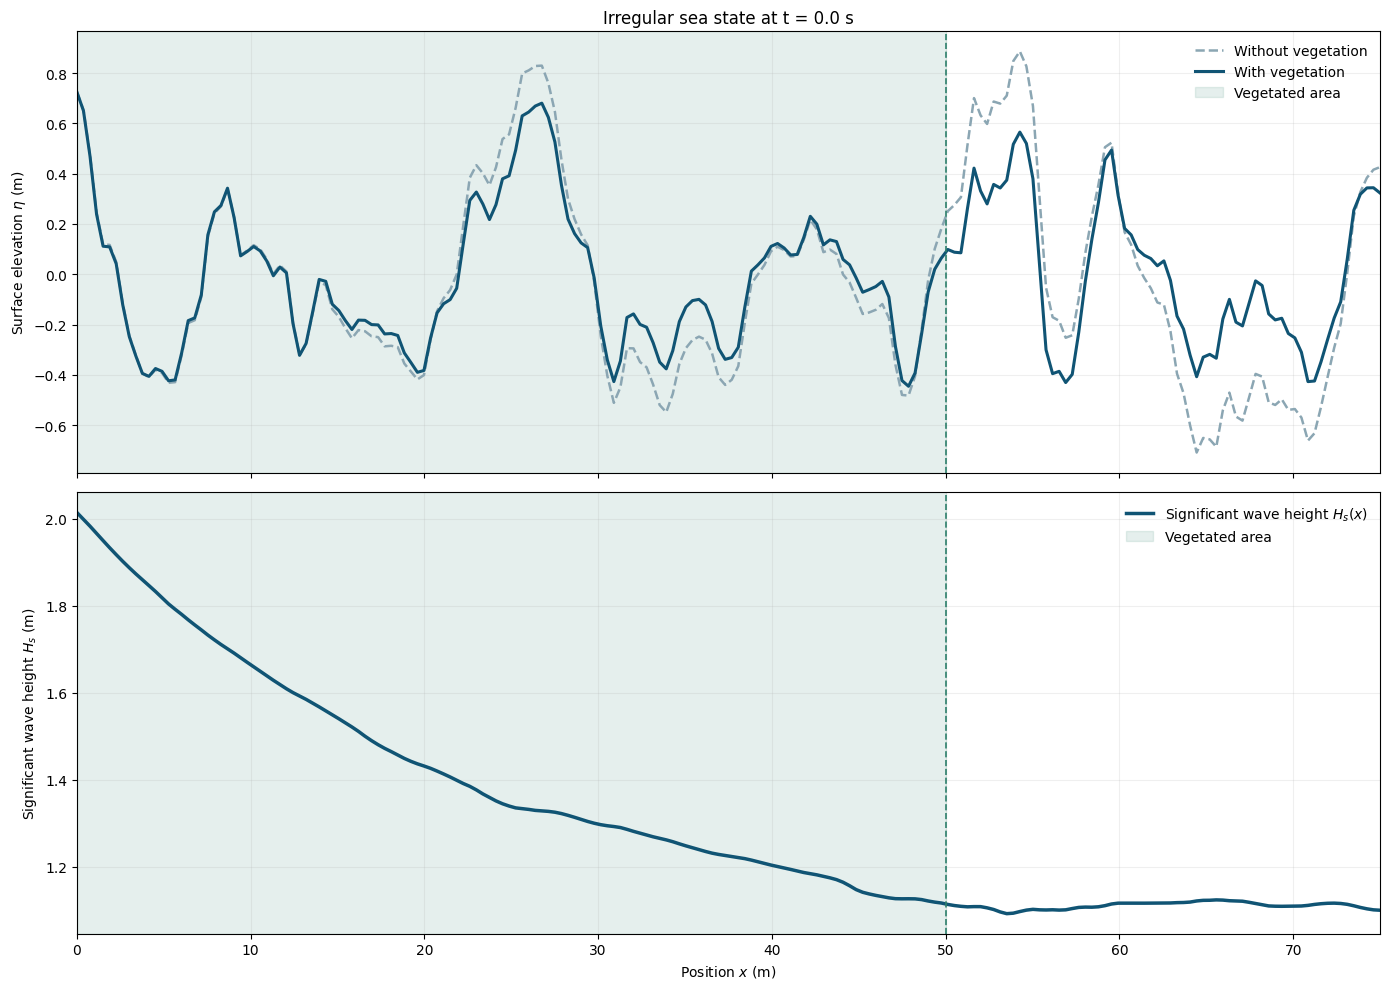

In [63]:
## Compare the same irregular sea state with and without vegetation.
## Both signals use identical frequencies, wave numbers and initial phases.

time_index = 0

eta_without_vegetation = eta_incident_xt[
    :,
    time_index
]

eta_with_vegetation = eta_xt[
    :,
    time_index
]


fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 10),
    sharex=True
)

axes[0].plot(
    x_irregular,
    eta_without_vegetation,
    color="#8ba6b3",
    linestyle="--",
    linewidth=1.8,
    label="Without vegetation"
)

axes[0].plot(
    x_irregular,
    eta_with_vegetation,
    color="#105474",
    linewidth=2.2,
    label="With vegetation"
)

axes[0].axvspan(
    0,
    L_vegetation,
    color="#2e806c",
    alpha=0.12,
    label="Vegetated area"
)

axes[0].axvline(
    L_vegetation,
    color="#2e806c",
    linestyle="--",
    linewidth=1.2
)

axes[0].set_ylabel("Surface elevation $\\eta$ (m)")
axes[0].set_title(
    f"Irregular sea state at t = "
    f"{time_record[time_index]:.1f} s"
)
axes[0].grid(alpha=0.2)
axes[0].legend(frameon=False)


axes[1].plot(
    x_irregular,
    Hs_profile,
    color="#105474",
    linewidth=2.5,
    label="Significant wave height $H_s(x)$"
)

axes[1].axvspan(
    0,
    L_vegetation,
    color="#2e806c",
    alpha=0.12,
    label="Vegetated area"
)

axes[1].axvline(
    L_vegetation,
    color="#2e806c",
    linestyle="--",
    linewidth=1.2
)

axes[1].set_xlabel("Position $x$ (m)")
axes[1].set_ylabel("Significant wave height $H_s$ (m)")
axes[1].grid(alpha=0.2)
axes[1].legend(frameon=False)

plt.xlim(0, 1.5 * L_vegetation)
plt.tight_layout()
plt.show()